In questo codice testo l'algoritmo di Nikolson per una condizione al bordo di cui è nota la g(t) risultante

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")
np.random.seed(42)

In [12]:
import heat1D_crank_nicolson_solver as cns

L = 0.5
Tf = 2500
nt = 50000
D = 0.001
wanted_r = 0.5

solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,0,wanted_r=wanted_r)
solver.info()

---------- Solver info
Time scale coeff:       2.50e+02
dx:                     1.00e-02
dt:                     5.00e-02
nt:                     50000
nx:                     51
r:                      5.00e-01


Slope (m): -3.9640201893750155e-11
Intercept (b): 0.9999999999978176
Expected Slope (m): 0.0
Slope (m): -0.4000000000002384
Intercept (b): 0.999999999999975
Expected Slope (m): -0.6666666666666666
Slope (m): -1.1111111111112295
Intercept (b): 0.9999999999999744
Expected Slope (m): -1.4285714285714286
Slope (m): -1.428571428571477
Intercept (b): 0.9999999999999751
Expected Slope (m): -1.6666666666666667
Slope (m): -1.6666666666666883
Intercept (b): 0.9999999999999799
Expected Slope (m): -1.8181818181818181


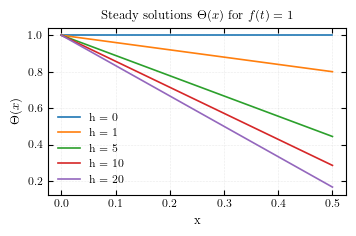

In [13]:

for h in [0,1,5,10,20]:

    solver.h = h
    solver._build_matrices() # Matrix B depend on h and has to be rebuild
     
    f = np.ones(nt)
    
    g = solver.solve(f)[:,-1]

    # Fit lineare
    m, b_fit = np.polyfit(solver.x_array, g, 1)

    print("Slope (m):", m)
    print("Intercept (b):", b_fit)
    print(f"Expected Slope (m): {-h/(1+h*L)}")

    plt.plot(solver.x_array, m*solver.x_array+b_fit, label=f"h = {h}")

plt.legend()
plt.title(r"Steady solutions $\Theta(x)$ for $f(t) = 1$")
plt.xlabel("x")
plt.ylabel(r"$\Theta(x)$")
plt.grid()
plt.savefig("assets/soluzione_lineare_nikolson.pdf")
plt.show()